Wymiary macierzy IR: (240, 320)
Min: 23.12 °C | Max: 37.14 °C


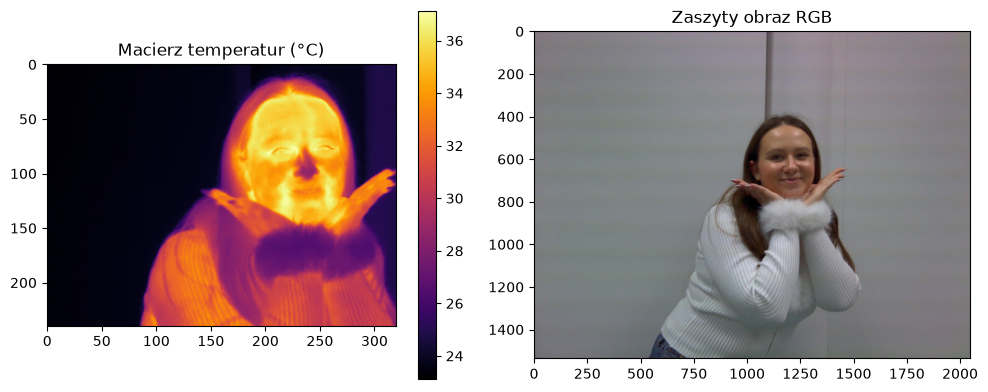

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt

sys.path.append(str(Path.cwd().parent))

from configs import settings
from src.thermal import extract_flir_data

thermal, rgb = extract_flir_data(settings.TEST_IR_PATH)

print(f"Wymiary macierzy IR: {thermal.shape}")
print(f"Min: {thermal.min():.2f} °C | Max: {thermal.max():.2f} °C")

# Szybki podgląd mapy temperatur i zaszytego RGB
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
im = axes[0].imshow(thermal, cmap="inferno")
axes[0].set_title("Macierz temperatur (°C)")
plt.colorbar(im, ax=axes[0])

axes[1].imshow(rgb)
axes[1].set_title("Zaszyty obraz RGB")
plt.tight_layout()
plt.show()

In [4]:
from pathlib import Path
import flyr

folder = settings.TEST_IR_PATH.parent

for p in sorted(folder.glob("*.jpg")):
    size_kb = p.stat().st_size / 1024
    raw_bytes = p.read_bytes()
    has_flir_tag = b"FLIR\x00" in raw_bytes
    
    try:
        t = flyr.unpack(str(p))
        status = f"OK -> {t.celsius.shape}"
    except Exception as e:
        status = f"BŁĄD ({type(e).__name__}: {e})"
        
    print(f"{p.name} | {size_kb:.0f} KB | tag FLIR: {has_flir_tag} | {status}")

FLIR2290.jpg | 323 KB | tag FLIR: True | OK -> (240, 320)
FLIR2291.jpg | 264 KB | tag FLIR: True | BŁĄD (KeyError: 1)
FLIR2292.jpg | 669 KB | tag FLIR: True | OK -> (240, 320)
FLIR2293.jpg | 411 KB | tag FLIR: True | BŁĄD (KeyError: 1)
FLIR2294.jpg | 722 KB | tag FLIR: True | OK -> (240, 320)
FLIR2295.jpg | 374 KB | tag FLIR: True | BŁĄD (KeyError: 1)
FLIR2296.jpg | 734 KB | tag FLIR: True | OK -> (240, 320)
FLIR2297.jpg | 433 KB | tag FLIR: True | BŁĄD (KeyError: 1)
FLIR2298.jpg | 501 KB | tag FLIR: True | OK -> (240, 320)
FLIR2299.jpg | 280 KB | tag FLIR: True | BŁĄD (KeyError: 1)
FLIR2300.jpg | 565 KB | tag FLIR: True | OK -> (240, 320)
FLIR2301.jpg | 311 KB | tag FLIR: True | BŁĄD (KeyError: 1)


In [ ]:
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
from configs import settings
from src.thermal import extract_flir_data
from src.face import detect_forehead_norm, map_bbox_to_matrix, calculate_roi_temp

thermal, _ = extract_flir_data(settings.TEST_IR_PATH)
norm_bbox = detect_forehead_norm(
    settings.TEST_RGB_PATH,
    settings.FOREHEAD_LANDMARKS,
    settings.FACE_MODEL_PATH,
    settings.FACE_MODEL_URL,
)
if norm_bbox is None:
    print("Status: ODRZUCONO (nie wykryto twarzy)")
else:
    bbox_ir = map_bbox_to_matrix(norm_bbox, thermal.shape)
    temp = calculate_roi_temp(thermal, bbox_ir, settings.TOP_PERCENTILE)
    print(f"Status: OK | Temp. czoła (top {100 - settings.TOP_PERCENTILE}%): {temp:.2f} °C")

    # Podgląd nałożenia ROI na RGB i IR
    rgb_img = plt.imread(str(settings.TEST_RGB_PATH))
    bbox_rgb = map_bbox_to_matrix(norm_bbox, rgb_img.shape[:2])

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, img, box, title, cmap in [
        (axes[0], rgb_img, bbox_rgb, "RGB + ROI", None),
        (axes[1], thermal, bbox_ir, f"IR ({temp:.2f} °C)", "inferno"),
    ]:
        ax.imshow(img, cmap=cmap)
        rect = patches.Rectangle((box[0], box[1]), box[2] - box[0], box[3] - box[1],
                                 linewidth=2, edgecolor="lime", facecolor="none")
        ax.add_patch(rect)
        ax.set_title(title)
    plt.tight_layout()
    plt.show()

AttributeError: module 'mediapipe' has no attribute 'solutions'